# **Problem Statement**

## **Business Context**

Workplace safety in hazardous environments like construction sites and industrial plants is crucial to prevent accidents and injuries. One of the most important safety measures is ensuring workers wear safety helmets, which protect against head injuries from falling objects and machinery. Non-compliance with helmet regulations increases the risk of serious injuries or fatalities, making effective monitoring essential, especially in large-scale operations where manual oversight is prone to errors and inefficiency.

To overcome these challenges, SafeGuard Corp plans to develop an automated image analysis system capable of detecting whether workers are wearing safety helmets. This system will improve safety enforcement, ensuring compliance and reducing the risk of head injuries. By automating helmet monitoring, SafeGuard aims to enhance efficiency, scalability, and accuracy, ultimately fostering a safer work environment while minimizing human error in safety oversight.

## **Objective**

As a data scientist at SafeGuard Corp, you are tasked with developing an image classification model that classifies images into one of two categories:
- **With Helmet:** Workers wearing safety helmets.
- **Without Helmet:** Workers not wearing safety helmets.

## **Data Description**

The dataset consists of **631 images**, equally divided into two categories:

- **With Helmet:** 311 images with helmets.
- **Without Helmet:** 320 images without helmets.

**Dataset Characteristics:**
- **Variations in Conditions:** Images include diverse environments such as construction sites, factories, and industrial settings, with variations in lighting, angles, and worker postures to simulate real-world conditions.
- **Worker Activities:** Workers are depicted in different actions such as standing, using tools, or moving, ensuring robust model learning for various scenarios.

# **Installing and Importing the Necessary Libraries**

**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [1]:
import os
import random
import numpy as np  # Importing numpy for Matrix Operations
import pandas as pd
import seaborn as sns
import matplotlib.image as mpimg  # Importing pandas to read CSV files
import matplotlib.pyplot as plt

# Importting matplotlib for Plotting and visualizing images
import math  # Importing math module to perform mathematical operations
import cv2

import sklearn

from sklearn import (preprocessing)
# Importing train_test_split function to split the data into train and test
from sklearn.model_selection import (train_test_split)
# Importing confusion_matrix to plot the confusion matrix
from sklearn.metrics import confusion_matrix

# Imports functions for evaluating the performance of machine learning models
from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    classification_report
)
from sklearn.metrics import (
    mean_squared_error as mse,
)  # Importing cv2_imshow from google.patches to display images


# Tensorflow modules
import keras
import tensorflow as tf
# Importing the ImageDataGenerator for data augmentation
from tensorflow.keras.preprocessing.image import (ImageDataGenerator)  
# Importing the sequential module to define a sequential model
from tensorflow.keras.models import (Sequential)
# Defining all the layers to build our CNN Model
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    Flatten,
    Conv2D,
    MaxPooling2D,
    BatchNormalization
)
# Importing the optimizers which can be used in our model
from tensorflow.keras.optimizers import (Adam, SGD) 
from tensorflow.keras.callbacks import EarlyStopping
# Importing the preprocessing module to preprocess the data

from tensorflow.keras.models import Model
from keras.applications.vgg16 import (VGG16)
# Display images using OpenCV
# from google.colab.patches import cv2_imshow

# Ignore warnings
import warnings

warnings.filterwarnings("ignore")
%matplotlib inline

In [2]:
print(f"numpy version: {np.__version__}")
print(f"pandas version: {pd.__version__}")
print(f"seaborn version: {sns.__version__}")
print(f"matplotlib version: {plt.matplotlib.__version__}")
print(f"OpenCV version: {cv2.__version__}")
print(f"scikit-learn version: {sklearn.__version__}")
print(f"TensorFlow version: {tf.__version__}")
print(f"Keras version: {keras.__version__}")

numpy version: 1.26.4
pandas version: 2.2.2
seaborn version: 0.13.2
matplotlib version: 3.8.3
OpenCV version: 4.8.1
scikit-learn version: 1.3.2
TensorFlow version: 2.18.0
Keras version: 3.5.0


In [3]:
#Check whether TensorFlow is using CUDA/GPU
gpus = tf.config.list_physical_devices('GPU')
print("GPU devices:", gpus)
if gpus:
    print("GPU is available and TensorFlow is using CUDA.")
else:
    print("No GPU detected. TensorFlow is using CPU.")

GPU devices: []
No GPU detected. TensorFlow is using CPU.


In [4]:
# Set the seed using keras.utils.set_random_seed. This will set:
# 1) `numpy` seed
# 2) backend random seed
# 3) `python` random seed
tf.keras.utils.set_random_seed(812)

# **Data Overview**


In [5]:
# from google.colab import drive
# drive.mount("/content/drive/")

## Loading the data

In [6]:
# images = np.load("/content/drive/MyDrive/AIML-Projects/Project6_CNN_HelmNet/images_proj.npy")

# labels = pd.read_csv("/content/drive/My Drive/AIML-Projects/Project6_CNN_HelmNet/Labels_proj.csv")

images = np.load("../data/raw_data/images_proj.npy")
labels = pd.read_csv("../data/raw_data/Labels_proj.csv")

In [7]:
print(f" images datatype: {type(images)}   shape: {images.shape}")
print(f" labels datatype: {type(labels)}   shape: {labels.shape}")

 images datatype: <class 'numpy.ndarray'>   shape: (631, 200, 200, 3)
 labels datatype: <class 'pandas.core.frame.DataFrame'>   shape: (631, 1)


In [8]:
print(f"Number of images: {images.shape[0]}")
print(f"Number of labels: {len(labels)}")

Number of images: 631
Number of labels: 631


In [9]:
labels.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 631 entries, 0 to 630
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Label   631 non-null    int64
dtypes: int64(1)
memory usage: 5.1 KB


In [10]:
# NUmber of missing labels
print(f"Number of missing labels: {labels.isnull().sum().sum()}")

Number of missing labels: 0


- There are no missing labels. All the images are associated with a corresponding label.

# **Exploratory Data Analysis**

In [11]:
num_images = images.shape[0]
print(f"Total number of images: {num_images}")

Total number of images: 631


In [12]:
print(f"Number of image classes: {labels.nunique()}")
# Number of imges of each class
labels["Label"].value_counts()

Number of image classes: Label    2
dtype: int64


Label
0    320
1    311
Name: count, dtype: int64

In [13]:
labels_dict = {0: "Without Helmet", 1: "With Helmet"}

### Plot random images from each of the classes and print their corresponding labels.

In [14]:
rand_idx = np.random.randint(5)

In [15]:
def plot_images(images, labels, rows, cols):
    fig = plt.figure(figsize=(10, 8))
    for i in range(rows):
        for j in range(cols):
            rand_indx = np.random.randint(0, len(labels))
            ax = fig.add_subplot(rows, cols, i * rows + j + 1)
            ax.imshow(images[rand_indx])
            ax.set_title(labels_dict[labels["Label"][rand_indx]])
    plt.tight_layout()
    plt.show()

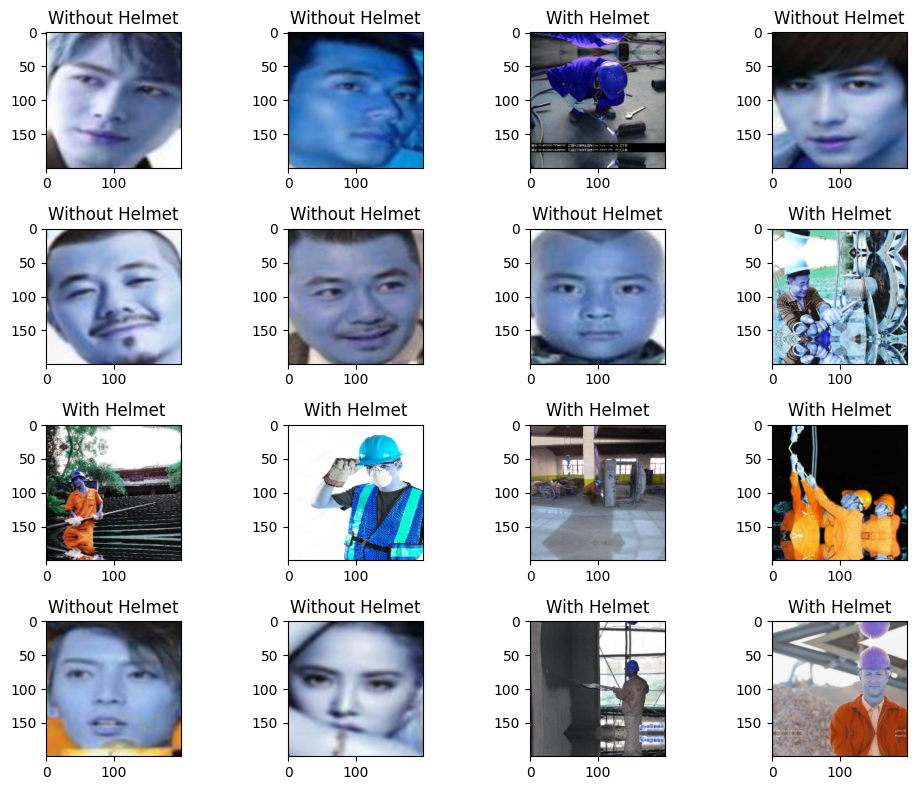

In [16]:
plot_images(images, labels, 4, 4)

## Checking for class imbalance


In [17]:
labels["Label"].value_counts()

Label
0    320
1    311
Name: count, dtype: int64

## Count plot of different classes

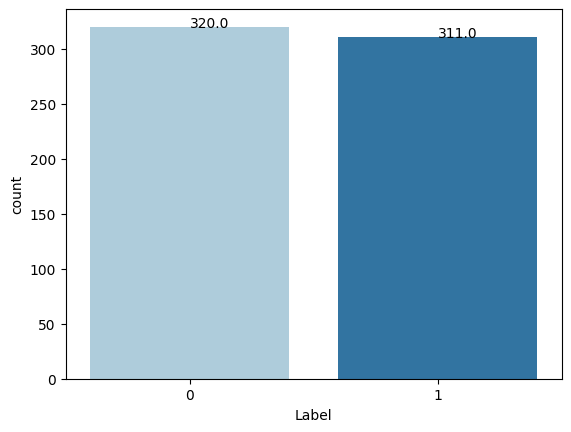

In [18]:
# countplot
ax = sns.countplot(labels, x=labels["Label"], stat="count", palette="Paired")
for p in ax.patches:
    x = p.get_x() + p.get_width() / 2
    y = p.get_y() + p.get_height()
    ax.annotate(p.get_height(), (x, y))

## Observations
- There are a total of 631 images
- Each image of dimensions 200x200 with 3 color channels
- Class Imbalance
  - There are 2 classes of images
   - 0 - Images do not include helmets
   - 1 - Images with people wearing helmets
  - Images are almost balanced between the two classes
  - 320 images belong to 'Without Helmet' class
  - 321 imges belong to 'With Helmet' class
- All the images are labeled
    - There are no missing labels




# **Data Preprocessing**

## Converting images to grayscale

In [19]:
gray_images = []
for i in range(len(images)):
    gray_images.append(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY))
gray_images = np.array(gray_images)

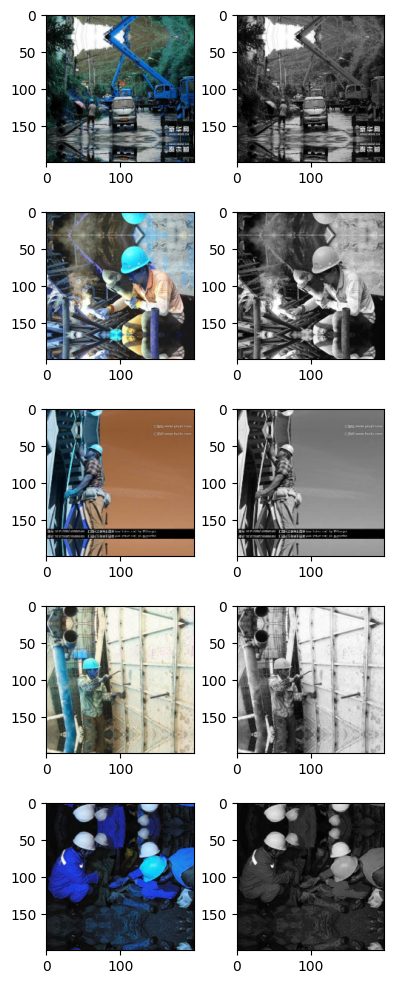

In [20]:
fig, ax = plt.subplots(5, 2, figsize=(4, 10))
for i in range(5):
    ax[i, 0].imshow(images[i])
    ax[i, 1].imshow(gray_images[i], cmap="gray")
plt.tight_layout()
plt.show()

## Converting Images to small size

In [21]:
# Efficient conversion - better than appending in a loop (pl. see conversion to gray images)
height = 64
width = 64
dimensions = (width, height)
small_images = np.array(
    [cv2.resize(img, dimensions, interpolation=cv2.INTER_LINEAR) for img in images]
)

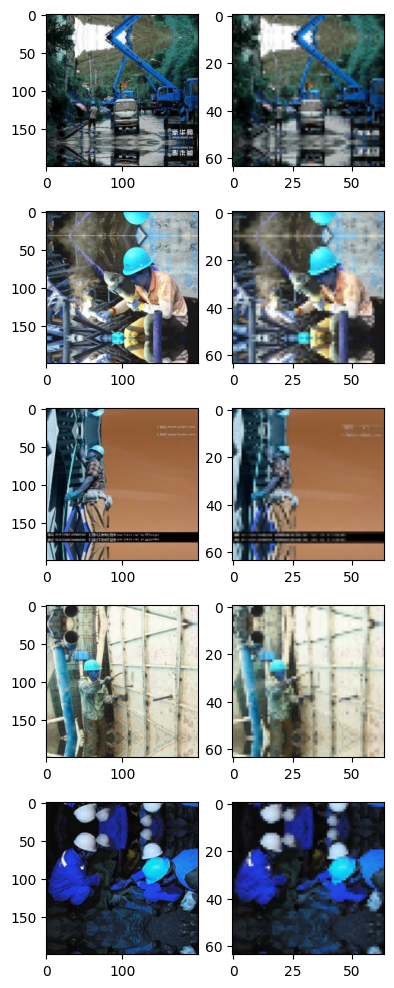

In [22]:
fig, ax = plt.subplots(5, 2, figsize=(4, 10))
for i in range(5):
    ax[i, 0].imshow(images[i])
    ax[i, 1].imshow(small_images[i])
plt.tight_layout()
plt.show()

In [23]:
print(f"images shape: {images.shape}")
print(f"gray_images shape: {gray_images.shape}")
print(f"small_images shape: {small_images.shape}")

images shape: (631, 200, 200, 3)
gray_images shape: (631, 200, 200)
small_images shape: (631, 64, 64, 3)


# Splitting the dataset



#### Splitting color images

In [24]:
# converting labels dataframe into numpy array
indices = np.arange(len(images))

In [25]:
# Split the imges into train and tep sets first with 80% images used for training and 20% imges used for validation and testing
X_train, X_temp, y_train, y_temp, idx_train, idx_temp = train_test_split(
    images, labels, indices, test_size=0.2, random_state=812, stratify=labels
)
# Verify the size and shape of train set
print(f" X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
# Verify the shape and size of temp set
print(f"X_temp shape: {X_temp.shape}, y_temp shape: {y_temp.shape}")

 X_train shape: (504, 200, 200, 3), y_train shape: (504, 1)
X_temp shape: (127, 200, 200, 3), y_temp shape: (127, 1)


In [26]:
# Split the temp set into validation and test sets equally with 10% of the all images each
X_val, X_test, y_val, y_test, idx_val, idx_test = train_test_split(
    X_temp, y_temp, idx_temp, test_size=0.5, random_state=812, stratify=y_temp
)
# Verify the shape and size of validation set
print(f"X_val shape: {X_val.shape}, y_val shape : {y_val.shape}")
# Verify the shape and size of test set
print(f"X_test shape: {X_test.shape}, y_test shape : {y_test.shape}")

X_val shape: (63, 200, 200, 3), y_val shape : (63, 1)
X_test shape: (64, 200, 200, 3), y_test shape : (64, 1)


#### Splitting gray images

In [27]:
X_train_gray, X_temp_gray, y_train_gray, y_temp_gray, idx_train_gray, idx_temp_gray = (
    train_test_split(
        gray_images, labels, indices, test_size=0.2, random_state=812, stratify=labels
    )
)

# Verify the size and shape of train set
print(
    f" X_train_gray shape: {X_train_gray.shape}, y_train_gray shape: {y_train_gray.shape}"
)
# Verify the shape and size of temp set
print(f"X_temp_gray shape: {X_temp_gray.shape}, y_temp_gray shape: {y_temp_gray.shape}")

 X_train_gray shape: (504, 200, 200), y_train_gray shape: (504, 1)
X_temp_gray shape: (127, 200, 200), y_temp_gray shape: (127, 1)


In [28]:
# split the temp set into validation and test sets
X_val_gray, X_test_gray, y_val_gray, y_test_gray, idx_val_gray, idx_test_gray = (
    train_test_split(
        X_temp_gray,
        y_temp_gray,
        idx_temp_gray,
        test_size=0.5,
        random_state=812,
        stratify=y_temp_gray,
    )
)

# Verify the shape and size of validation and test sets
print(f"X_val_gray shape: {X_val_gray.shape}, y_val_gray shape : {y_val_gray.shape}")
# Verify the shape and size of validation and test sets
print(
    f"X_test_gray shape: {X_test_gray.shape}, y_test_gray shape : {y_test_gray.shape}"
)

X_val_gray shape: (63, 200, 200), y_val_gray shape : (63, 1)
X_test_gray shape: (64, 200, 200), y_test_gray shape : (64, 1)


### Data Normalization

#### Divide all the image pixel values with 255 to get the intensities within the range 0-1
- We do this preprocessing after splitting into train, validation and test sets to prevent any data leakage or contamination

In [29]:
# Normalizing the image pixels
X_train_norm = X_train.astype("float32") / 255.0
X_val_norm = X_val.astype("float32") / 255.0
X_test_norm = X_test.astype("float32") / 255.0
print(
    f" X_train: {X_train_norm[:,:,:].min()}   X_train Max: {X_train_norm[:, :, :].max()}"
)
print(
    f" X_val: {X_val_norm[:,:,:].min()}     X_val_norm Max: {X_train_norm[:, :, :].max()}"
)
print(
    f" X_test: {X_test_norm[:,:,:].min()}    X_test_norm Max: {X_train_norm[:, :, :].max()}"
)

 X_train: 0.0   X_train Max: 1.0
 X_val: 0.0     X_val_norm Max: 1.0
 X_test: 0.0    X_test_norm Max: 1.0


In [30]:
# Normalizing the image pixels
X_train_gray_norm = X_train_gray.astype("float32") / 255.0
X_val_gray_norm = X_val_gray.astype("float32") / 255.0
X_test_gray_norm = X_test_gray.astype("float32") / 255.0
print(
    f" X_train_gray_norm Min: {X_train_gray_norm[:,:,:].min()}   X_train_gray_norm Max: {X_train_gray_norm[:, :, :].max()}"
)
print(
    f" X_val_gray_norm Min: {X_val_gray_norm[:,:,:].min()}   X_val_gray_norm Max: {X_val_gray_norm[:, :, :].max()}"
)
print(
    f" X_test_gray_norm Min: {X_test_gray_norm[:,:,:].min()}   X_test_gray_norm Max: {X_test_gray_norm[:, :, :].max()}"
)

 X_train_gray_norm Min: 0.0   X_train_gray_norm Max: 1.0
 X_val_gray_norm Min: 0.0   X_val_gray_norm Max: 1.0
 X_test_gray_norm Min: 0.0   X_test_gray_norm Max: 1.0


# **Model Building**

In [31]:
batch_size = 32
random_state = 812  # to be consistent with what was used earlier

## Model Evaluation Criterion

- f1_score is chosen as the metric as it is important to know how many of the workers wear helmet and how many don't wear helmet

## Utility Functions

In [32]:
# Function to compute predictions given model and predictors
def get_model_predictions(model, predictors):
    # checking which probabilities are greater than threshold
    pred_prob = model.predict(predictors)
    predictions = (pred_prob >= 0.5).astype(int).reshape(-1)
    return predictions

In [33]:
# Function to plot loss, val_loss,
def plot_history(history):
    N = len(history.history["f1_score"])
    plt.figure()
    plt.plot(np.arange(0, N), history.history["f1_score"], label="train_f1_score")
    plt.plot(np.arange(0, N), history.history["val_f1_score"], label="val_f1_score")
    plt.title("Training Dataset")
    plt.xlabel("Epoch #")
    plt.ylabel("f1_score")
    plt.legend(loc="upper right")

In [34]:
# defining a function to compute different metrics to check performance of a classification model built using statsmodels
def model_performance_metrics(targets, predictions):
    """
    Function to compute different metrics to check classification model performance
    predictions: Predicted values
    targets:     Actual values
    returns:     A dataframe of all 4 performance metrics:
                 Accuracy, Precision, Recall, F1-score
    """
    # compute Accuracy
    acc = accuracy_score(targets, predictions)
    # compute Recall
    recall = recall_score(targets, predictions, average="weighted")
    # compute Precision
    precision = precision_score(targets, predictions, average="weighted")
    # compute F1-score
    f1 = f1_score(targets, predictions, average="weighted")

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "Accuracy": acc,
            "Recall": recall,
            "Precision": precision,
            "F1 Score": f1,
        },
        index=[0],
    )
    return df_perf

In [35]:
def plot_confusion_matrix(targets, predictions):
    """
    Function to plot the confusion matrix
    predictions: Predicted values
    targets:     Actual values
    returns:     None
    """
    # Plotting the Confusion Matrix using confusion matrix() function which is also predefined tensorflow module
    confusion_matrix = tf.math.confusion_matrix(targets, predictions)
    f, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(
        confusion_matrix, annot=True, linewidths=0.4, fmt="d", square=True, ax=ax
    )
    plt.show()

In [36]:
def plot_image_labels(image, pred, label):
    plt.figure(figsize=(2, 2))
    print(f"True      Label: {label}")
    print(f"Predicted Label: {pred}")
    plt.imshow(image)
    plt.show()

In [37]:
def model_performance(model, predictors, targets):
    # model predictions on training data
    predictions = get_model_predictions(model, predictors)
    # model performance metrics dataframe on training data
    df_metrics = model_performance_metrics(targets, predictions)
    print(df_metrics)
    # model confusion matrix on training data
    plot_confusion_matrix(targets, predictions)
    return df_metrics

In [38]:
early_stop = EarlyStopping(
    monitor="val_f1_score",  # metric to watch
    patience=2,  # how many epochs to wait without improvement
    mode="max",  # "max" for accuracy/F1, "min" for loss
    restore_best_weights=True,  # revert to best epoch weights
)

## Model 1 - Very Simple CNN Model

#### Model 1 - Architecture

In [39]:
# Model architecture
model_cnn_1 = Sequential()

# Convolution layers
model_cnn_1.add(
    Conv2D(
        filters=4,
        kernel_size=(3, 3),
        padding="same",
        activation="relu",
        input_shape=(200, 200, 3),
    )
)
model_cnn_1.add(MaxPooling2D(2, 2))


model_cnn_1.add(
    Conv2D(filters=4, kernel_size=(3, 3), padding="same", activation="relu")
)
model_cnn_1.add(MaxPooling2D(2, 2))

# Flattening layer
model_cnn_1.add(Flatten())

# Fully Connected layers with dropouts
model_cnn_1.add(Dense(8, activation="relu"))
model_cnn_1.add(Dropout(0.25))
model_cnn_1.add(Dense(4, activation="relu"))

# Outputlayer - single neuron with sigmoid as this is a binary classification
model_cnn_1.add(Dense(1, activation="sigmoid"))

In [40]:
model_cnn_1.compile(loss="binary_crossentropy", optimizer="sgd", metrics=["f1_score"])
model_cnn_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 200, 200, 4)    │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 100, 100, 4)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 100, 100, 4)    │           148 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 50, 50, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │        80,008 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 80,309 (313.71 KB)

 Trainable params: 80,309 (313.71 KB)

 Non-trainable params: 0 (0.00 B)

In [41]:
# model convergence
model_cnn_1_history = model_cnn_1.fit(
    X_train_norm,
    y_train,
    epochs=20,
    validation_data=(X_val_norm, y_val),
    shuffle=True,
    batch_size=batch_size,
    verbose=2,
)

Epoch 1/20
16/16 - 1s - 69ms/step - f1_score: 0.6596 - loss: 0.6714 - val_f1_score: 0.6596 - val_loss: 0.6397
Epoch 2/20
16/16 - 0s - 30ms/step - f1_score: 0.6596 - loss: 0.6276 - val_f1_score: 0.6596 - val_loss: 0.5933
Epoch 3/20
16/16 - 0s - 28ms/step - f1_score: 0.6596 - loss: 0.5780 - val_f1_score: 0.6596 - val_loss: 0.5515
Epoch 4/20
16/16 - 0s - 28ms/step - f1_score: 0.6596 - loss: 0.5534 - val_f1_score: 0.6596 - val_loss: 0.5269
Epoch 5/20
16/16 - 0s - 28ms/step - f1_score: 0.6596 - loss: 0.5336 - val_f1_score: 0.6596 - val_loss: 0.5281
Epoch 6/20
16/16 - 0s - 28ms/step - f1_score: 0.6596 - loss: 0.5164 - val_f1_score: 0.6596 - val_loss: 0.4871
Epoch 7/20
16/16 - 0s - 28ms/step - f1_score: 0.6596 - loss: 0.4878 - val_f1_score: 0.6596 - val_loss: 0.4485
Epoch 8/20
16/16 - 0s - 30ms/step - f1_score: 0.6596 - loss: 0.4673 - val_f1_score: 0.6596 - val_loss: 0.4714
Epoch 9/20
16/16 - 0s - 28ms/step - f1_score: 0.6596 - loss: 0.4427 - val_f1_score: 0.6596 - val_loss: 0.3919
Epoch 10/2

#### Model 1 - Performance on Train set

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
   Accuracy    Recall  Precision  F1 Score
0  0.970238  0.970238   0.970433   0.97024


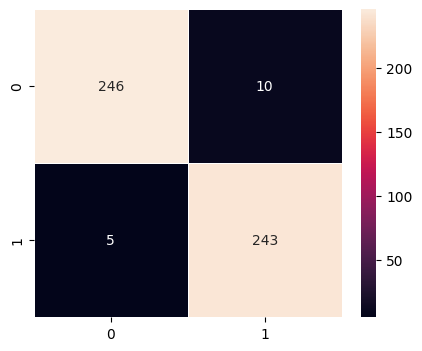

In [42]:
# model predictions on training data
model_cnn_1_y_train_pred = get_model_predictions(model_cnn_1, X_train_norm)
# model performance metrics dataframe on training data
model_cnn_1_train_perf_df = model_performance_metrics(y_train, model_cnn_1_y_train_pred)
print(model_cnn_1_train_perf_df)

# model confusion matrix on training data
plot_confusion_matrix(y_train, model_cnn_1_y_train_pred)

#### Model 1 - Performance on Validation set

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
   Accuracy    Recall  Precision  F1 Score
0  0.936508  0.936508   0.938214  0.936412


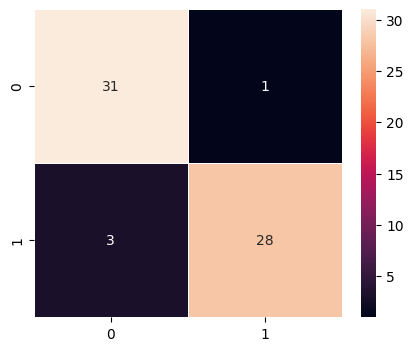

In [43]:
# model predictions on validation data
model_cnn_1_y_val_pred = get_model_predictions(model_cnn_1, X_val_norm)
# model performance metrics dataframe on validation data
model_cnn_1_val_perf_df = model_performance_metrics(y_val, model_cnn_1_y_val_pred)
print(model_cnn_1_val_perf_df)
# model confusion matrix on validation data
plot_confusion_matrix(y_val, model_cnn_1_y_val_pred)

#### Model 1 - Visualization of some images

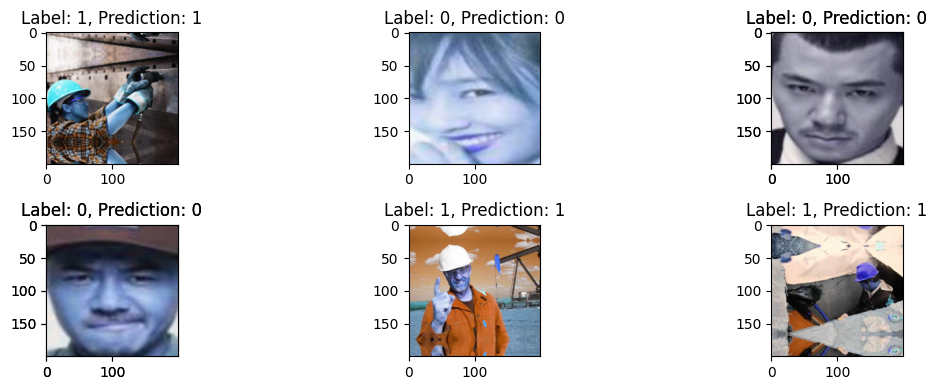

Number of misclassified images : 4
Misclassified Images


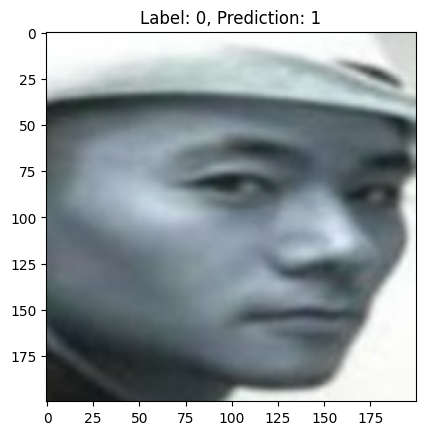

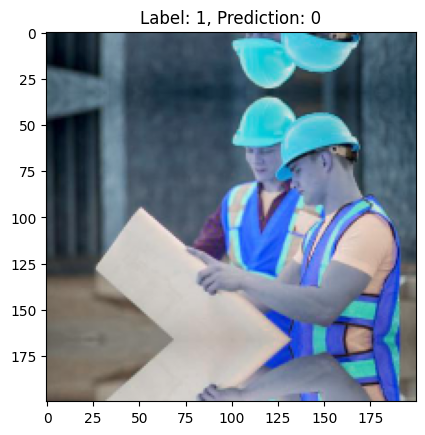

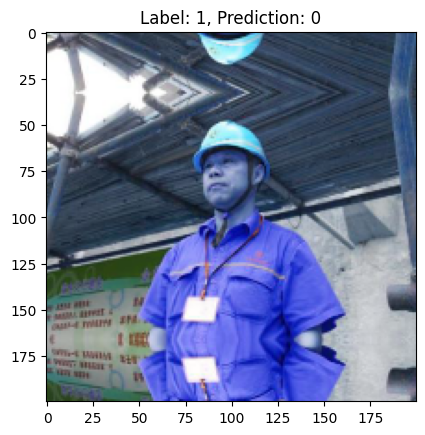

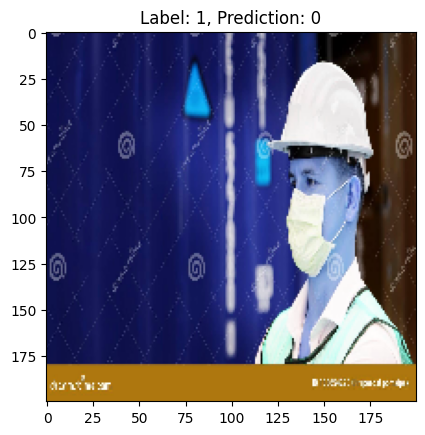

In [44]:
# display some validation images along with the lable and prediction
y_pred = model_cnn_1_y_val_pred
y_true = y_val.to_numpy().reshape(-1)

# indices within the validation split
misclassified = np.where(y_pred != y_true)[0]

# original indices of the misclassified validation set examples
original_miscalssified = idx_val[misclassified]

misclassified_images = X_val[misclassified]

num_misclassified = len(misclassified_images)

# visualize some images along with their predicted and true labels
fig = plt.figure(figsize=(12, 4))
for i in range(2):
    for j in range(4):
        indx = i * 2 + j + 1
        orig_indx = idx_val[indx]
        ax = fig.add_subplot(2, 3, i * 2 + j + 1)
        ax.imshow(X_val[indx])
        ax.set_title(f"Label: {y_true[indx]}, Prediction: {y_pred[indx]}")
plt.tight_layout()
plt.show()


print(f"Number of misclassified images : {num_misclassified}")
if num_misclassified > 0:
    print("Misclassified Images")
    for i in misclassified[:5]:
        orig_indx = idx_val[i]
        img = X_val[i]
        plt.imshow(img)
        plt.title(f"Label: {y_true[i]}, Prediction: {y_pred[i]}")
        plt.show()

### Observations

- This is a very simple CNN model with only 2 convolution layer each of them followed by a pooling layer
- Very less number of filter (4) used in each of the convolution layer
- The dense layers also contain less number of neurons 8 and 4  respectively
- This is a small data set with two well balanced classes (With and Without helmet).

- 'binary_crossentropy' is used as the loss function as this is a bianry classification problem
- SGD optimiser is used
- F1-score metric used to check the performance

- The images are very distinct between the two classes
- The images without helmet appear like closeup shots
- As the images are so distinct that even this simple model was able to give an F1-score of about 97% on training and 94% on validation data sets


- 3 images with helmets are predicted as without helmet
- 1 image without helmet is predicted as with helmet. In this case, the person wore a cap. It is probably misread by the model as helmet.

## Model 1a: Simple CNN - Color Images

#### Model 1a - Architecture

In [45]:
# Model architecture
model_cnn_rgb = Sequential()

# Convolution layers
model_cnn_rgb.add(
    Conv2D(
        filters=64,
        kernel_size=(3, 3),
        padding="same",
        activation="relu",
        input_shape=(200, 200, 3),
    )
)
model_cnn_rgb.add(MaxPooling2D(2, 2))


model_cnn_rgb.add(
    Conv2D(filters=32, kernel_size=(3, 3), padding="same", activation="relu")
)
model_cnn_rgb.add(MaxPooling2D(2, 2))


model_cnn_rgb.add(
    Conv2D(filters=16, kernel_size=(3, 3), padding="same", activation="relu")
)
model_cnn_rgb.add(MaxPooling2D(2, 2))


# Flattening layer
model_cnn_rgb.add(Flatten())

# Fully Connected layers with dropouts
model_cnn_rgb.add(Dense(64, activation="relu"))
model_cnn_rgb.add(Dropout(0.25))
model_cnn_rgb.add(Dense(32, activation="relu"))

# Outputlayer - single neuron with sigmoid as this is a binary classification
model_cnn_rgb.add(Dense(1, activation="sigmoid"))

In [46]:
model_cnn_rgb.compile(
    loss="binary_crossentropy", optimizer="adam", metrics=["f1_score"]
)
model_cnn_rgb.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 200, 200, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 100, 100, 32)   │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 50, 50, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 25, 25, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 10000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       640,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 667,057 (2.54 MB)

 Trainable params: 667,057 (2.54 MB)

 Non-trainable params: 0 (0.00 B)

In [47]:
# model convergence
model_cnn_rgb_history = model_cnn_rgb.fit(
    X_train_norm,
    y_train,
    epochs=10,
    validation_data=(X_val_norm, y_val),
    shuffle=True,
    batch_size=batch_size,
    verbose=2,
)

Epoch 1/10
16/16 - 6s - 366ms/step - f1_score: 0.6596 - loss: 0.5429 - val_f1_score: 0.6596 - val_loss: 0.1016
Epoch 2/10
16/16 - 4s - 276ms/step - f1_score: 0.6596 - loss: 0.1841 - val_f1_score: 0.6596 - val_loss: 0.0486
Epoch 3/10
16/16 - 4s - 265ms/step - f1_score: 0.6596 - loss: 0.1291 - val_f1_score: 0.6596 - val_loss: 0.1260
Epoch 4/10
16/16 - 5s - 296ms/step - f1_score: 0.6596 - loss: 0.0627 - val_f1_score: 0.6596 - val_loss: 0.0146
Epoch 5/10
16/16 - 5s - 291ms/step - f1_score: 0.6596 - loss: 0.0255 - val_f1_score: 0.6596 - val_loss: 0.0382
Epoch 6/10
16/16 - 4s - 275ms/step - f1_score: 0.6596 - loss: 0.0232 - val_f1_score: 0.6596 - val_loss: 0.0143
Epoch 7/10
16/16 - 5s - 286ms/step - f1_score: 0.6596 - loss: 0.0189 - val_f1_score: 0.6596 - val_loss: 0.0875
Epoch 8/10
16/16 - 5s - 286ms/step - f1_score: 0.6596 - loss: 0.0181 - val_f1_score: 0.6596 - val_loss: 0.0099
Epoch 9/10
16/16 - 5s - 284ms/step - f1_score: 0.6596 - loss: 0.0092 - val_f1_score: 0.6596 - val_loss: 0.0014
E

#### Model 1a - Performance on Train set

16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step
   Accuracy    Recall  Precision  F1 Score
0  0.998016  0.998016   0.998024  0.998016


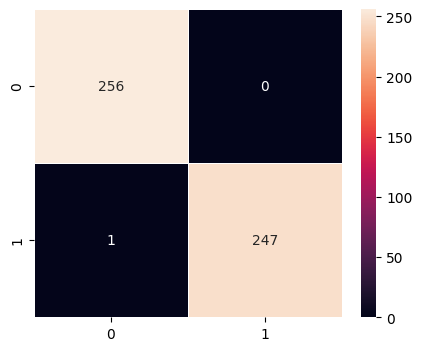

In [48]:
# model predictions on training data
model_cnn_rgb_y_train_pred = get_model_predictions(model_cnn_rgb, X_train_norm)
# model performance metrics dataframe on training data
model_cnn_rgb_train_perf_df = model_performance_metrics(
    y_train, model_cnn_rgb_y_train_pred
)
print(model_cnn_rgb_train_perf_df)

# model confusion matrix on training data
plot_confusion_matrix(y_train, model_cnn_rgb_y_train_pred)

#### Model 1a - Performance on Validation set

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


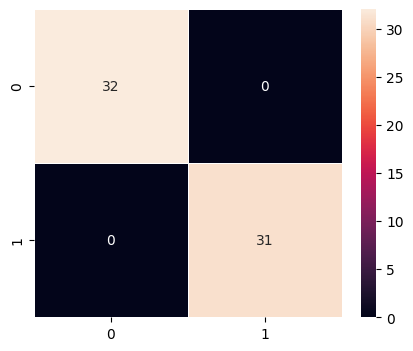

In [49]:
# model predictions on validation data
model_cnn_rgb_y_val_pred = get_model_predictions(model_cnn_rgb, X_val_norm)
# model performance metrics dataframe on validation data
model_cnn_rgb_val_perf_df = model_performance_metrics(y_val, model_cnn_rgb_y_val_pred)
print(model_cnn_rgb_val_perf_df)
# model confusion matrix on validation data
plot_confusion_matrix(y_val, model_cnn_rgb_y_val_pred)

#### Model 1a - Visualizing the predictions

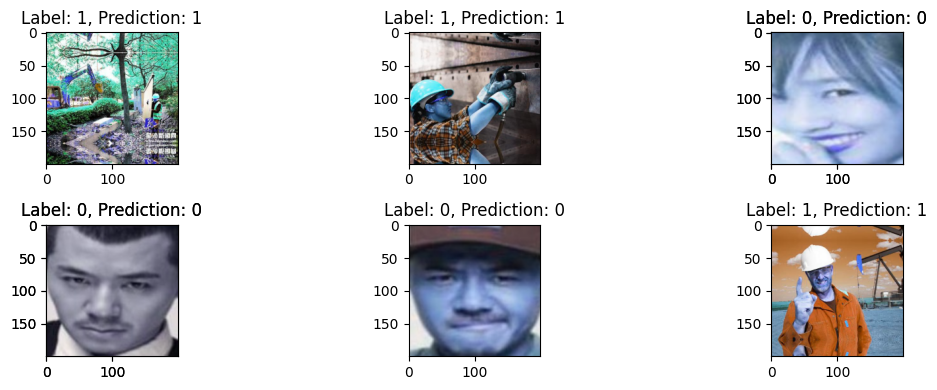

Number of misclassified images : 0


In [50]:
# display some validation images along with the lable and prediction
y_pred = model_cnn_rgb_y_val_pred
y_true = y_val.to_numpy().reshape(-1)

# indices within the validation split
misclassified = np.where(y_pred != y_true)[0]

# original indices of the misclassified validation set examples
original_miscalssified = idx_val[misclassified]

misclassified_images = X_val[misclassified]

num_misclassified = len(misclassified_images)

# visualize some images along with their predicted and true labels
fig = plt.figure(figsize=(12, 4))
for i in range(2):
    for j in range(4):
        indx = i * 2 + j
        orig_indx = idx_val[indx]
        ax = fig.add_subplot(2, 3, i * 2 + j + 1)
        ax.imshow(X_val[indx])
        ax.set_title(f"Label: {y_true[indx]}, Prediction: {y_pred[indx]}")
plt.tight_layout()
plt.show()

print(f"Number of misclassified images : {num_misclassified}")
if num_misclassified > 0:
    print("Misclassified Images")
    for i in misclassified[:5]:
        orig_indx = idx_val[i]
        img = X_val[i]
        plt.imshow(img)
        plt.title(f"Label: {y_true[i]}, Prediction: {y_pred[i]}")
        plt.show()

### Observations
- The model architecture has multiple convolution layers with many filters
- Padding is used to maintain the same image size after each convolution
- Each of the convolution layers is followed by a pooling layer.
- The fully connected part of the model has multiple dense layers with many neurons
- Sigmoid function is used for activation in the output layer as this is a binary classification problem
- For the same reason, binary_classentropy is used as the loss function
- The model has a total of 667,057 parameters. 
- For this simple data set where the two classes are very distinct from each other, model is easily able to classify with 100% accuracy on training as well as validation sets
- The model seems to be big enough for this relatively simple data set.

## Model 1b: Simple CNN - Gray Images

#### Model 1b - Architecture

In [51]:
# Model architecture
model_cnn_gray = Sequential()

# Convolution layers
model_cnn_gray.add(
    Conv2D(
        filters=256,
        kernel_size=(3, 3),
        padding="same",
        activation="relu",
        input_shape=(200, 200, 1),
    )
)
model_cnn_gray.add(MaxPooling2D(2, 2))


model_cnn_gray.add(
    Conv2D(filters=64, kernel_size=(3, 3), padding="same", activation="relu")
)
model_cnn_gray.add(
    Conv2D(filters=64, kernel_size=(3, 3), padding="same", activation="relu")
)
model_cnn_gray.add(MaxPooling2D(2, 2))


model_cnn_gray.add(
    Conv2D(filters=32, kernel_size=(3, 3), padding="same", activation="relu")
)
model_cnn_gray.add(MaxPooling2D(2, 2))


# Flattening layer
model_cnn_gray.add(Flatten())

# Fully Connected layers with dropouts
model_cnn_gray.add(Dense(256, activation="relu"))
model_cnn_gray.add(Dropout(0.25))
model_cnn_gray.add(Dense(64, activation="relu"))

# Outputlayer - single neuron with sigmoid as this is a binary classification
model_cnn_gray.add(Dense(1, activation="sigmoid"))

In [52]:
opt = Adam()
model_cnn_gray.compile(loss="binary_crossentropy", optimizer=opt, metrics=["f1_score"])
model_cnn_gray.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 200, 200, 256)  │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 100, 100, 256)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 100, 100, 64)   │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 100, 100, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 50, 50, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 25, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 20000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │     5,120,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,342,241 (20.38 MB)

 Trainable params: 5,342,241 (20.38 MB)

 Non-trainable params: 0 (0.00 B)

In [53]:
model_cnn_gray_history = model_cnn_gray.fit(
    X_train_gray_norm,
    y_train_gray,
    epochs=10,
    validation_data=(X_val_gray_norm, y_val_gray),
    shuffle=True,
    batch_size=batch_size,
    verbose=2,
)

Epoch 1/10
16/16 - 26s - 2s/step - f1_score: 0.6596 - loss: 0.6785 - val_f1_score: 0.6596 - val_loss: 0.5930
Epoch 2/10
16/16 - 23s - 1s/step - f1_score: 0.6596 - loss: 0.2529 - val_f1_score: 0.6596 - val_loss: 0.0979
Epoch 3/10
16/16 - 23s - 1s/step - f1_score: 0.6596 - loss: 0.0620 - val_f1_score: 0.6596 - val_loss: 0.0251
Epoch 4/10
16/16 - 24s - 1s/step - f1_score: 0.6596 - loss: 0.1452 - val_f1_score: 0.6596 - val_loss: 0.0173
Epoch 5/10
16/16 - 23s - 1s/step - f1_score: 0.6596 - loss: 0.0298 - val_f1_score: 0.6596 - val_loss: 0.0203
Epoch 6/10
16/16 - 24s - 2s/step - f1_score: 0.6596 - loss: 0.0150 - val_f1_score: 0.6596 - val_loss: 0.0017
Epoch 7/10
16/16 - 25s - 2s/step - f1_score: 0.6596 - loss: 0.0257 - val_f1_score: 0.6596 - val_loss: 0.0449
Epoch 8/10
16/16 - 24s - 1s/step - f1_score: 0.6596 - loss: 0.0112 - val_f1_score: 0.6596 - val_loss: 5.2784e-04
Epoch 9/10
16/16 - 25s - 2s/step - f1_score: 0.6596 - loss: 2.4224e-04 - val_f1_score: 0.6596 - val_loss: 1.0630e-04
Epoch 1

#### Model 1b - Performance on Train set

In [54]:
pred_prob = model_cnn_gray.predict(X_train_gray_norm)
pred_prob[:5]

16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 414ms/step


array([[2.4614330e-06],
       [3.9867307e-05],
       [1.0000000e+00],
       [1.3785041e-05],
       [1.0000000e+00]], dtype=float32)

16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 414ms/step
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


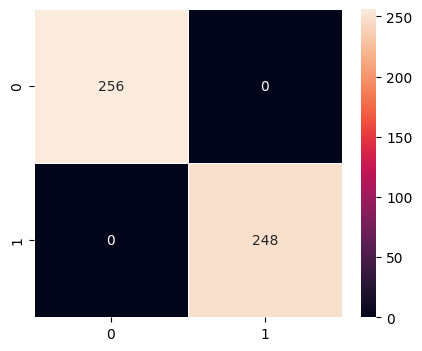

In [55]:
# model predictions on training data
model_cnn_gray_y_train_pred = get_model_predictions(model_cnn_gray, X_train_gray_norm)
# model performance metrics dataframe on training data
model_cnn_gray_train_perf_df = model_performance_metrics(
    y_train_gray, model_cnn_gray_y_train_pred
)
print(model_cnn_gray_train_perf_df)
# model confusion matrix on training data
plot_confusion_matrix(y_train_gray, model_cnn_gray_y_train_pred)

#### Model 1b - Performance on Validation set

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 397ms/step
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


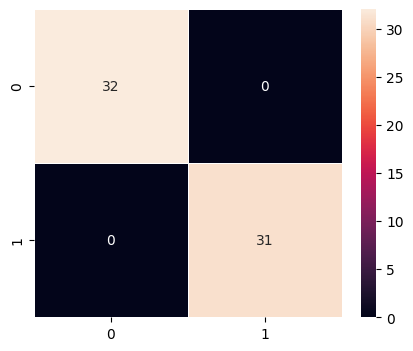

In [56]:
# model predictions on training data
model_cnn_gray_y_val_pred = get_model_predictions(model_cnn_gray, X_val_gray_norm)
# model performance metrics dataframe on training data
model_cnn_gray_val_perf_df = model_performance_metrics(
    y_val_gray, model_cnn_gray_y_val_pred
)
print(model_cnn_gray_val_perf_df)
# model confusion matrix on training data
plot_confusion_matrix(y_val_gray, model_cnn_gray_y_val_pred)

### Model 1b - Visualizing the predictions

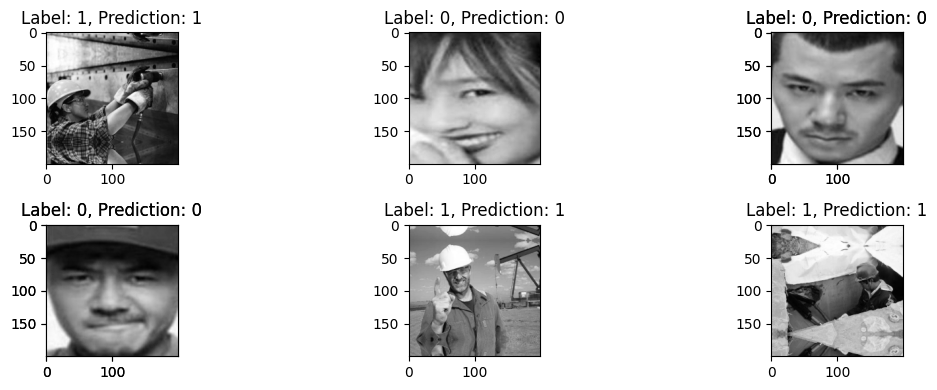

Number of misclassified images : 0


In [57]:
# display some validation images along with the lable and prediction
y_pred = model_cnn_gray_y_val_pred
y_true = y_val_gray.to_numpy().reshape(-1)

# indices within the validation split
misclassified = np.where(y_pred != y_true)[0]

# original indices of the misclassified validation set examples
original_miscalssified = idx_val_gray[misclassified]

misclassified_images = X_val_gray[misclassified]

num_misclassified = len(misclassified_images)

# visualize some images along with their predicted and true labels
fig = plt.figure(figsize=(12, 4))
for i in range(2):
    for j in range(4):
        indx = i * 2 + j + 1
        orig_indx = idx_val_gray[indx]
        ax = fig.add_subplot(2, 3, i * 2 + j + 1)
        ax.imshow(X_val_gray[indx], cmap="gray")
        ax.set_title(f"Label: {y_true[indx]}, Prediction: {y_pred[indx]}")
plt.tight_layout()
plt.show()

print(f"Number of misclassified images : {num_misclassified}")
if num_misclassified > 0:
    print("Misclassified Images")
    for i in misclassified[:5]:
        orig_indx = idx_val[i]
        img = X_val_gray[i]
        plt.imshow(img, cmap="gray")
        plt.title(f"Label: {y_true[i]}, Prediction: {y_pred[i]}")
        plt.show()

### Observations - with model using gray images
- The model architecture has multiple convolution layers with many filters
- The model is very large with a total of 5,343,649 parameters.
- The gray images are used for training the data set.
- For this simple data set where the two classes are very distinct from each other, model is easily able to classify with 100% accuracy on training as well as validation sets
- The model seems to be big enough for this relatively simple data set.

- All the images with helmets are predicted correctly
-  images without helmet are predicted as with helmet. 
  - In one case, the person wore a cap. It is probably misread by the model as helmet.
  - In second case, due to a clear contrast in color, the hair is probably mistaken as helmet.

## Model 2: (VGG-16 (Base))

In [58]:
vgg_model = VGG16(weights="imagenet", include_top=False, input_shape=(200, 200, 3))
vgg_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 200, 200, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 200, 200, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 100, 100, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 100, 100, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 50, 50, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 50, 50, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 50, 50, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 25, 25, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 25, 25, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 25, 25, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 25, 25, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 12, 12, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 6, 6, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [59]:
# Making all the layers of the VGG model non-trainable. i.e. freezing them
for layer in vgg_model.layers:
    layer.trainable = False

In [60]:
for layer in vgg_model.layers:
    print(layer.name, layer.trainable)

input_layer_3 False
block1_conv1 False
block1_conv2 False
block1_pool False
block2_conv1 False
block2_conv2 False
block2_pool False
block3_conv1 False
block3_conv2 False
block3_conv3 False
block3_pool False
block4_conv1 False
block4_conv2 False
block4_conv3 False
block4_pool False
block5_conv1 False
block5_conv2 False
block5_conv3 False
block5_pool False


#### Model 2 - Architecture

In [61]:
model_vgg16_base = Sequential()

# Adding the convolutional part of the VGG16 model from above
model_vgg16_base.add(vgg_model)

# Flattening the output of the VGG16 model because it is from a convolutional layer
model_vgg16_base.add(Flatten())

# Adding a dense output layer
model_vgg16_base.add(Dense(1, "sigmoid"))

In [62]:
opt = Adam()
# compile model
model_vgg16_base.compile(
    loss="binary_crossentropy", optimizer=opt, metrics=["f1_score"]
)

In [63]:
model_vgg16_base.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 6, 6, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │        18,433 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,733,121 (56.20 MB)

 Trainable params: 18,433 (72.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [64]:
## Fitting the VGG model
model_vgg16_base_history = model_vgg16_base.fit(
    x=X_train_norm,
    y=y_train,
    validation_data=(X_val_norm, y_val),
    callbacks=[early_stop],
    epochs=10,
)
# plot_history(model_vgg16_base_history)

Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - f1_score: 0.6731 - loss: 0.4171 - val_f1_score: 0.6596 - val_loss: 0.0154
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - f1_score: 0.6731 - loss: 0.0127 - val_f1_score: 0.6596 - val_loss: 0.0039
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - f1_score: 0.6731 - loss: 0.0051 - val_f1_score: 0.6596 - val_loss: 0.0025


#### Model 2 - Performance on Train set

16/16 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step
   Accuracy    Recall  Precision  F1 Score
0  0.998016  0.998016   0.998024  0.998016


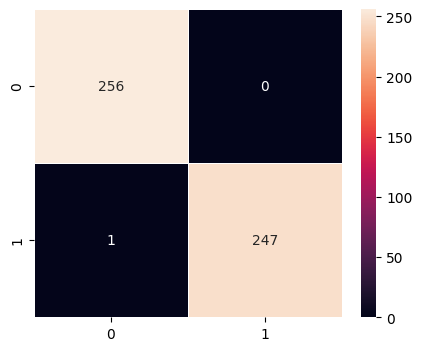

In [65]:
# model predictions on training data
model_vgg16_base_y_train_pred = get_model_predictions(model_vgg16_base, X_train_norm)
# model performance metrics dataframe on training data
model_vgg16_base_train_perf_df = model_performance_metrics(
    y_train, model_vgg16_base_y_train_pred
)
print(model_vgg16_base_train_perf_df)

# model confusion matrix on training data
plot_confusion_matrix(y_train, model_vgg16_base_y_train_pred)

#### Model 2 - Performance on Validation set

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


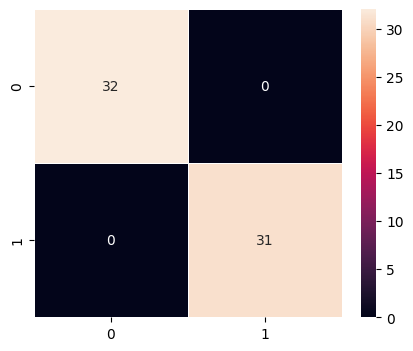

In [66]:
# model predictions on validation data
model_vgg16_base_y_val_pred = get_model_predictions(model_vgg16_base, X_val_norm)
# model performance metrics dataframe on validation data
model_vgg16_base_val_perf_df = model_performance_metrics(
    y_val, model_vgg16_base_y_val_pred
)
print(model_vgg16_base_val_perf_df)
# model confusion matrix on validation data
plot_confusion_matrix(y_val, model_vgg16_base_y_val_pred)

### Model 2 - Visualizing the prediction:

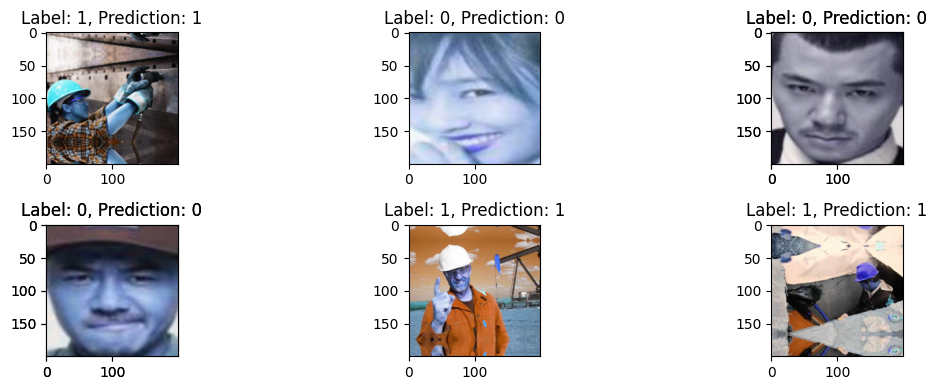

Number of misclassified images : 0


In [67]:
# display some validation images along with the lable and prediction
y_pred = model_vgg16_base_y_val_pred
y_true = y_val.to_numpy().reshape(-1)

# indices within the validation split
misclassified = np.where(y_pred != y_true)[0]

# original indices of the misclassified validation set examples
original_miscalssified = idx_val[misclassified]

misclassified_images = X_val[misclassified]

num_misclassified = len(misclassified_images)

# visualize some images along with their predicted and true labels
fig = plt.figure(figsize=(12, 4))
for i in range(2):
    for j in range(4):
        indx = i * 2 + j + 1
        orig_indx = idx_val[indx]
        ax = fig.add_subplot(2, 3, i * 2 + j + 1)
        ax.imshow(X_val[indx])
        ax.set_title(f"Label: {y_true[indx]}, Prediction: {y_pred[indx]}")
plt.tight_layout()
plt.show()


print(f"Number of misclassified images : {num_misclassified}")
if num_misclassified > 0:
    print("Misclassified Images")
    for img in misclassified_images[:5]:
        plt.imshow(img)
        plt.title(f"Label: {y_true[i]}, Prediction: {y_pred[i]}")
        plt.show()

### Observations - Transfer Learning with VGG16
- The VGG16 model is used for the convolution part
- THe output from the convoultion is flattened and used as input to the only output layer.
- No other dense layers are used

  - The model has 14,733,121 total parameters
  - However, only 18,433 are trainable parameters, rest of them are non-trainable parameters from VGG16
- For this simple data set, where the two classes are very distinct from each other, model is easily able to classify with 100% accuracy on training as well as validation sets
- The model seems to be big enough for this relatively simple data set.

## Model 3: (VGG-16 (Base + FFNN))

#### Model 3 - Architecture

In [68]:
model_vgg16_ffnn = Sequential()

# Adding the convolutional part of the VGG16 model from above
model_vgg16_ffnn.add(vgg_model)

# Flattening the output of the VGG16 model because it is from a convolutional layer
model_vgg16_ffnn.add(Flatten())

# Adding the Feed Forward neural network
model_vgg16_ffnn.add(Dense(64, activation="relu"))
model_vgg16_ffnn.add(Dropout(rate=0.25))
model_vgg16_ffnn.add(Dense(32, activation="relu"))
model_vgg16_ffnn.add(Dropout(rate=0.25))
model_vgg16_ffnn.add(Dense(16, activation="relu"))

# Adding a dense output layer
model_vgg16_ffnn.add(Dense(1, activation="sigmoid"))

In [69]:
opt = Adam()
# Compile model
model_vgg16_ffnn.compile(
    optimizer=opt, loss="binary_crossentropy", metrics=["f1_score"]
)

In [70]:
model_vgg16_ffnn.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 6, 6, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │     1,179,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,897,025 (60.64 MB)

 Trainable params: 1,182,337 (4.51 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [71]:
model_vgg16_ffnn_history = model_vgg16_ffnn.fit(
    X_train_norm,
    y_train,
    validation_data=(X_val_norm, y_val),
    callbacks=[early_stop],
    epochs=10,
)

Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - f1_score: 0.6731 - loss: 0.5621 - val_f1_score: 0.6596 - val_loss: 0.0330
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - f1_score: 0.6731 - loss: 0.0903 - val_f1_score: 0.6596 - val_loss: 0.0018


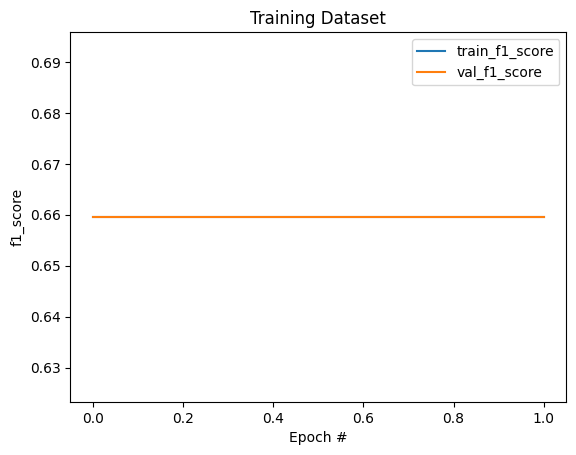

In [72]:
plot_history(model_vgg16_ffnn_history)

#### Model 3 - Performance on Train set

16/16 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step
model_vgg16_ffnn_train_perf_df Train performance
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


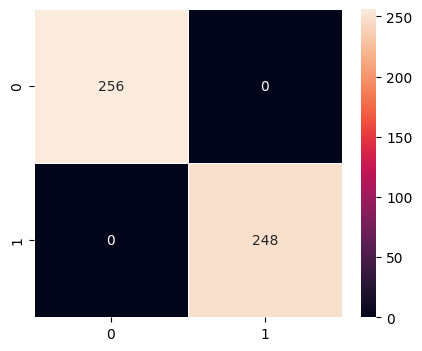

In [73]:
# model predictions on training data
model_vgg16_ffnn_y_train_pred = get_model_predictions(model_vgg16_ffnn, X_train_norm)
# model performance metrics dataframe on training data
model_vgg16_ffnn_train_perf_df = model_performance_metrics(
    y_train, model_vgg16_ffnn_y_train_pred
)
print("model_vgg16_ffnn_train_perf_df Train performance")
print(model_vgg16_ffnn_train_perf_df)

# model confusion matrix on training data
plot_confusion_matrix(y_train, model_vgg16_ffnn_y_train_pred)

#### Model 3 - Performance on Validation set

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step
model_vgg16_ffnn_val_perf_df Validation performance
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


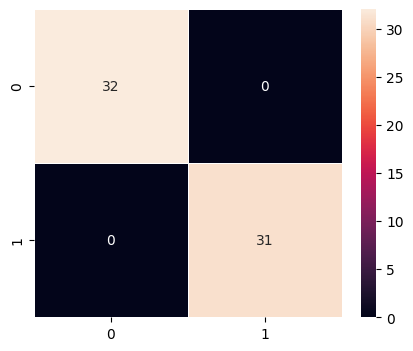

In [74]:
# model predictions on validation data
model_vgg16_ffnn_y_val_pred = get_model_predictions(model_vgg16_ffnn, X_val_norm)
# model performance metrics dataframe on validation data
model_vgg16_ffnn_val_perf_df = model_performance_metrics(
    y_val, model_vgg16_ffnn_y_val_pred
)
print("model_vgg16_ffnn_val_perf_df Validation performance")
print(model_vgg16_ffnn_val_perf_df)
# model confusion matrix on validation data
plot_confusion_matrix(y_val, model_vgg16_ffnn_y_val_pred)

#### Model 3 - Visualizing the predictions

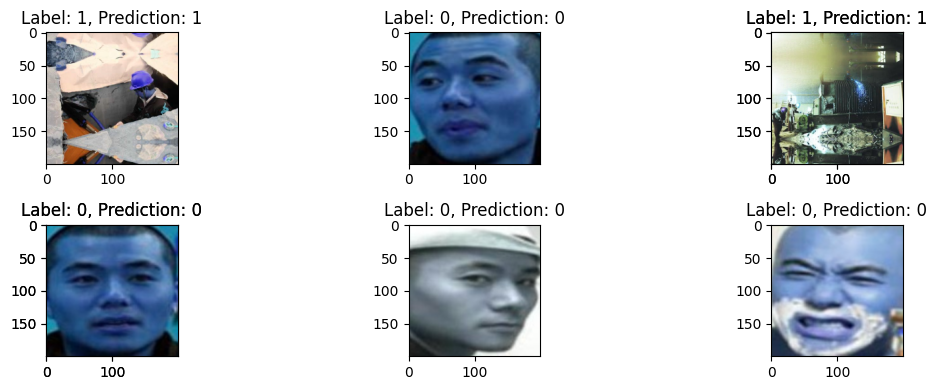

Number of misclassified images : 0


In [75]:
# Boolean mask version
y_pred = model_vgg16_ffnn_y_val_pred
y_true = y_val.to_numpy().reshape(-1)

# indices within the validation split
misclassified = np.where(y_pred != y_true)[0]

# original indices of the misclassified validation set examples
original_miscalssified = idx_val[misclassified]

misclassified_images = X_val[misclassified]

num_misclassified = len(misclassified_images)

# visualize some images along with their predicted and true labels
fig = plt.figure(figsize=(12, 4))
for i in range(2):
    for j in range(4):
        indx = i * 2 + j + 1 + 5
        orig_indx = idx_val[indx]
        ax = fig.add_subplot(2, 3, i * 2 + j + 1)
        ax.imshow(X_val[indx])
        ax.set_title(f"Label: {y_true[indx]}, Prediction: {y_pred[indx]}")
plt.tight_layout()
plt.show()


print(f"Number of misclassified images : {num_misclassified}")
if num_misclassified > 0:
    print("Misclassified Images")
    for img in misclassified_images[:5]:
        plt.imshow(img)
        plt.title(f"Label: {y_true[i]}, Prediction: {y_pred[i]}")
        plt.show()

### Observations - Transfer Learning with VGG16
- The VGG16 model is used for the convolution part
- A fully connected network with 3 dense layers with multiple neurons is used with ReLU activations
- An output layer with 'sigmoid' activation is used

  - The model has 15,897,025 total parameters
  - However, only 1,182,337 are trainable parameters, rest of them are non-trainable parameters from VGG16
- For this simple data set, where the two classes are very distinct from each other, model is easily able to classify with 100% accuracy on training as well as validation sets
- The model seems to be big enough for this relatively simple data set.

## Model 4: (VGG-16 (Base + FFNN + Data Augmentation)

- In most of the real-world case studies, it is challenging to acquire a large number of images and then train CNNs.
- To overcome this problem, one approach we might consider is **Data Augmentation**.
- CNNs have the property of **translational invariance**, which means they can recognise an object even if its appearance shifts translationally in some way. - Taking this attribute into account, we can augment the images using the techniques listed below

    -  Horizontal Flip (should be set to True/False)
    -  Vertical Flip (should be set to True/False)
    -  Height Shift (should be between 0 and 1)
    -  Width Shift (should be between 0 and 1)
    -  Rotation (should be between 0 and 180)
    -  Shear (should be between 0 and 1)
    -  Zoom (should be between 0 and 1) etc.

Remember, **data augmentation should not be used in the validation/test data set**.

#### Model 4 - Architecture

In [76]:
model_vgg16_aug = Sequential()

# Adding the convolutional part of the VGG16 model from above
model_vgg16_aug.add(vgg_model)

# Flattening the output of the VGG16 model because it is from a convolutional layer
model_vgg16_aug.add(Flatten())

# Adding the Feed Forward neural network
model_vgg16_aug.add(Dense(256, activation="relu"))
model_vgg16_aug.add(Dropout(rate=0.25))
model_vgg16_aug.add(Dense(64, activation="relu"))
model_vgg16_aug.add(Dropout(rate=0.25))
model_vgg16_aug.add(Dense(32, activation="relu"))

# Adding a dense output layer
model_vgg16_aug.add(Dense(1, activation="sigmoid"))

In [77]:
opt = Adam()

In [78]:
# Compile model
model_vgg16_aug.compile(optimizer=opt, loss="binary_crossentropy", metrics=["f1_score"])

In [79]:
model_vgg16_aug.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 6, 6, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 256)            │     4,718,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,452,097 (74.20 MB)

 Trainable params: 4,737,409 (18.07 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

#### Data Augmentation

In [80]:
# Applying data augmentation
train_datagen = ImageDataGenerator(
    rotation_range=20,
    fill_mode="nearest",
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.3,
    zoom_range=0.4,
)

#### Displaying some augmented images

In [81]:
train_generator = train_datagen.flow(X_train_norm, y_train, batch_size=batch_size)
# get one batch of augmented images
augmented_images, augmented_labels = next(train_generator)

In [82]:
model_vgg16_aug_history = model_vgg16_aug.fit(
    train_datagen.flow(X_train_norm, y_train, batch_size=batch_size),
    validation_data=(X_val_norm, y_val),
    callbacks=[early_stop],
    epochs=20,
)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - f1_score: 0.6251 - loss: 0.4923 - val_f1_score: 0.6596 - val_loss: 7.8347e-04
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - f1_score: 0.6310 - loss: 0.0290 - val_f1_score: 0.6596 - val_loss: 2.6324e-05


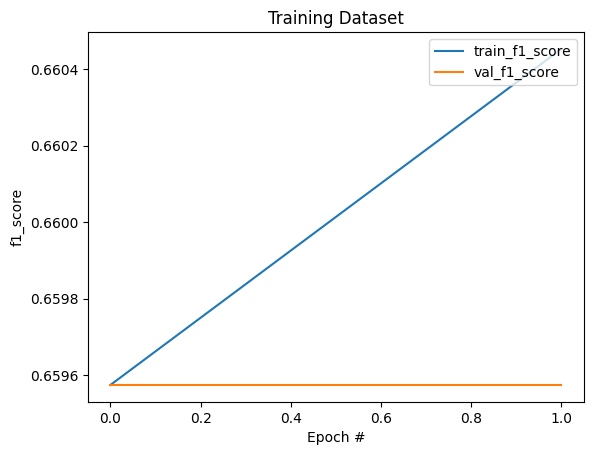

In [83]:
plot_history(model_vgg16_aug_history)

#### Model 4 - Performance on Train set

16/16 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step
model_vgg16_aug_train_perf_df Train performance
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


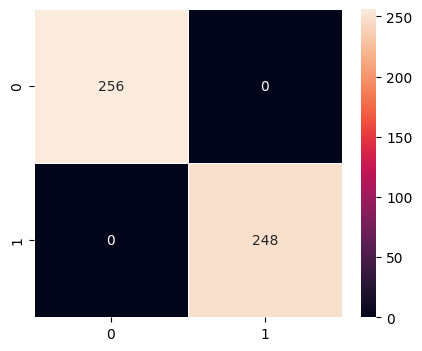

In [84]:
# model predictions on training data
model_vgg16_aug_y_train_pred = get_model_predictions(model_vgg16_aug, X_train_norm)
# model performance metrics dataframe on training data
model_vgg16_aug_train_perf_df = model_performance_metrics(
    y_train, model_vgg16_aug_y_train_pred
)
print("model_vgg16_aug_train_perf_df Train performance")
print(model_vgg16_aug_train_perf_df)

# model confusion matrix on training data
plot_confusion_matrix(y_train, model_vgg16_aug_y_train_pred)

#### Model 4 - Performance on Validation set

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step
model_vgg16_aug_val_perf_df Validation performance
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


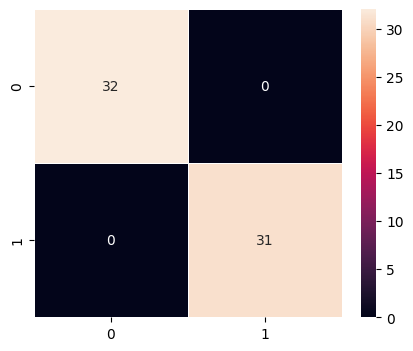

In [85]:
# model predictions on validation data
model_vgg16_aug_y_val_pred = get_model_predictions(model_vgg16_aug, X_val_norm)
# model performance metrics dataframe on validation data
model_vgg16_aug_val_perf_df = model_performance_metrics(
    y_val, model_vgg16_aug_y_val_pred
)
print("model_vgg16_aug_val_perf_df Validation performance")
print(model_vgg16_aug_val_perf_df)
# model confusion matrix on validation data
plot_confusion_matrix(y_val, model_vgg16_aug_y_val_pred)

#### Model 4 - Visualizing the predictions

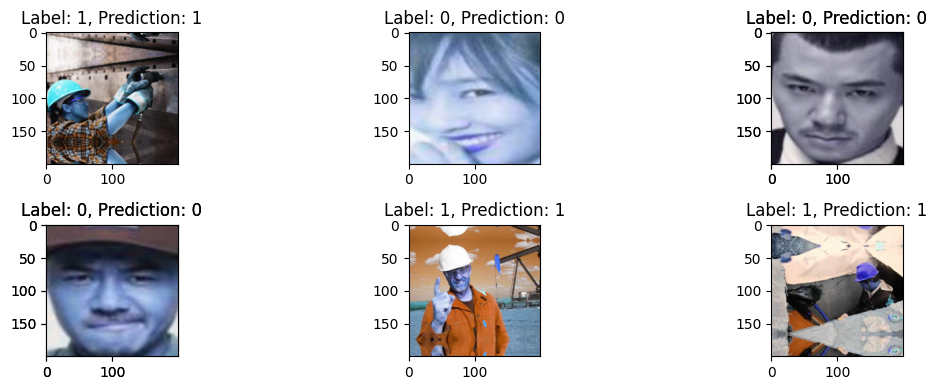

Number of misclassified images : 0


In [86]:
y_pred = model_vgg16_aug_y_val_pred
y_true = y_val.to_numpy().reshape(-1)

# indices within the validation split
misclassified = np.where(y_pred != y_true)[0]

# original indices of the misclassified validation set examples
original_miscalssified = idx_val[misclassified]

misclassified_images = X_val[misclassified]

num_misclassified = len(misclassified_images)

# visualize some images along with their predicted and true labels
fig = plt.figure(figsize=(12, 4))
for i in range(2):
    for j in range(4):
        indx = i * 2 + j + 1
        orig_indx = idx_val[indx]
        ax = fig.add_subplot(2, 3, i * 2 + j + 1)
        ax.imshow(X_val[indx])
        ax.set_title(f"Label: {y_true[indx]}, Prediction: {y_pred[indx]}")
plt.tight_layout()
plt.show()


print(f"Number of misclassified images : {num_misclassified}")
if num_misclassified > 0:
    print("Misclassified Images")
    for img in misclassified_images[:5]:
        plt.imshow(img)
        plt.title(f"Label: {y_true[i]}, Prediction: {y_pred[i]}")
        plt.show()

### Observations - Transfer Learning with VGG16 and Data augmentation
- The VGG16 model is used for the convolution part
- A fully connected network with 3 dense layers with multiple neurons is used with ReLU activations
- 'binary_crossentropy' is used as the loss function as this is a bianry classification problem
- An output layer with 'sigmoid' activation is used

  - The model has 4,737,409 trainable parameters
  - Early stoipping is used, thus stopping the epochs after 3 epochs
- For this simple data set, where the two classes are very distinct from each other, model is easily able to classify with 100% accuracy on training as well as validation sets
- The model seems to be big enough for this relatively simple data set.

# **Model Performance Comparison and Final Model Selection**

In [87]:
# Performance comaprison on train set
df_models_train_perf = pd.concat(
    [
        model_cnn_1_train_perf_df.T,
        model_cnn_rgb_train_perf_df.T,
        model_cnn_gray_train_perf_df.T,
        model_vgg16_base_train_perf_df.T,
        model_vgg16_ffnn_train_perf_df.T,
        model_vgg16_aug_train_perf_df.T,
    ],
    axis=1,
)
df_models_train_perf.columns = [
    "CNN-Simple",
    "CNN-RGB",
    "CNN-Gray",
    "VGG-16(Base)",
    "VGG-16(Base+FFNN)",
    "VGG-16(DataAug",
]
print(df_models_train_perf)

           CNN-Simple   CNN-RGB  CNN-Gray  VGG-16(Base)  VGG-16(Base+FFNN)  \
Accuracy     0.970238  0.998016       1.0      0.998016                1.0   
Recall       0.970238  0.998016       1.0      0.998016                1.0   
Precision    0.970433  0.998024       1.0      0.998024                1.0   
F1 Score     0.970240  0.998016       1.0      0.998016                1.0   

           VGG-16(DataAug  
Accuracy              1.0  
Recall                1.0  
Precision             1.0  
F1 Score              1.0  


In [88]:
# Performance comaprison on validation set
df_models_val_perf = pd.concat(
    [
        model_cnn_1_val_perf_df.T,
        model_cnn_rgb_val_perf_df.T,
        model_cnn_gray_val_perf_df.T,
        model_vgg16_base_val_perf_df.T,
        model_vgg16_ffnn_val_perf_df.T,
        model_vgg16_aug_val_perf_df.T,
    ],
    axis=1,
)
df_models_val_perf.columns = [
    "CNN-Simple",
    "CNN-RGB",
    "CNN-Gray",
    "VGG-16(Base)",
    "VGG-16(Base+FFNN)",
    "VGG-16(DataAug)",
]
print(df_models_val_perf)

           CNN-Simple  CNN-RGB  CNN-Gray  VGG-16(Base)  VGG-16(Base+FFNN)  \
Accuracy     0.936508      1.0       1.0           1.0                1.0   
Recall       0.936508      1.0       1.0           1.0                1.0   
Precision    0.938214      1.0       1.0           1.0                1.0   
F1 Score     0.936412      1.0       1.0           1.0                1.0   

           VGG-16(DataAug)  
Accuracy               1.0  
Recall                 1.0  
Precision              1.0  
F1 Score               1.0  


### Observations
- A very simple CNN model achieved 94% on all performance metrics on validation set
- Relatively complex CNN models performed better than simple model. 98% on RGB model vs 97% on gray model on validation data set.
- A CNN model using color images yielded  better performance than a similar model with gray images.

## Test Performance

All the models performed great on this data set.
The data set is small with two classes of images that are very different from each other.
Model3 i.e., VGG16 + Base + FFNN is chosen as for testing on the test data set


2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step
model_vgg16_ffnn_test_perf_df Test performance
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


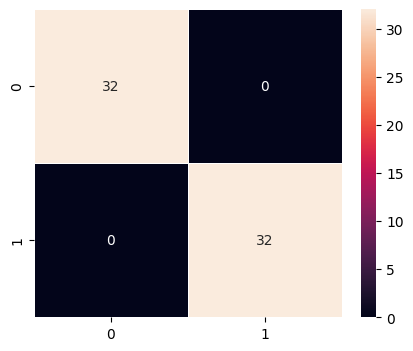

In [89]:
# model predictions on validation data
model_vgg16_ffnn_y_test_pred = get_model_predictions(model_vgg16_ffnn, X_test_norm)
# model performance metrics dataframe on validation data
model_vgg16_ffnn_test_perf_df = model_performance_metrics(
    y_test, model_vgg16_ffnn_y_test_pred
)
print("model_vgg16_ffnn_test_perf_df Test performance")
print(model_vgg16_ffnn_test_perf_df)
# model confusion matrix on validation data
plot_confusion_matrix(y_test, model_vgg16_ffnn_y_test_pred)

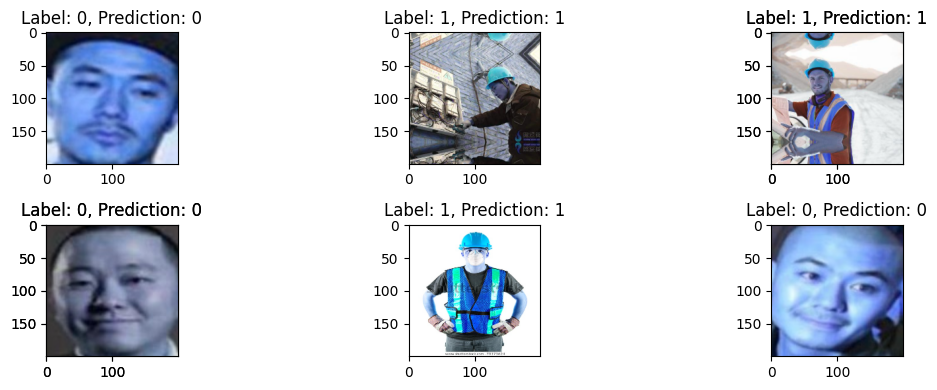

In [90]:
# display some test images along with the lable and prediction
y_pred = model_vgg16_ffnn_y_test_pred
y_true = y_test.to_numpy().reshape(-1)

# indices within the validation split
misclassified = np.where(y_pred != y_true)[0]

# original indices of the misclassified validation set examples
original_miscalssified = idx_test[misclassified]

misclassified_images = X_test[misclassified]

num_misclassified = len(misclassified_images)

# visualize some images along with their predicted and true labels
fig = plt.figure(figsize=(12, 4))
for i in range(2):
    for j in range(4):
        indx = i * 2 + j + 1
        orig_indx = idx_test[indx]
        ax = fig.add_subplot(2, 3, i * 2 + j + 1)
        ax.imshow(X_test[indx])
        ax.set_title(f"Label: {y_true[indx]}, Prediction: {y_pred[indx]}")
plt.tight_layout()
plt.show()

# **Actionable Insights & Recommendations**

### Summary:
 - A wide variety of Six models with diverse convolution neural networks architecture are studied.
 - Color images and also gray scale images are used to study the model behaviour on different types of images.
 - 'binary_crossentropy' is used as the loss function as this is a bianry classification problem
 - Adam or SGD optimiser are used
 - F1-score metric used to check the performance
 - 'sigmoid' activation is used in the output layer
 - Performances of all the models are summarized.
 - Except for the very simple model with less number of convolution layers and filters, other models yielded near 100% accuracy on training and validation sets.
 - More epochs are needed in the case of very simple model
 - Model where gray scale images are used, although relatively large architecture is used, misclassified some of the images.

### Actionable Insights and Business Recommendations
- This appears to be a simple data set with a very distinct type of images for each class
- There are two classes of images, 'With Helmet' and 'Without Helmet'
- Images belong to 'Without Helmet class appear to be close up shots or profile pictures, and do not represent the workplace scenario.
- Hence, safety practices are to be evaluated, profile pictures may not serve well for the purpose.
- Dataset must contain better representative images i.e., all the images in the dataset should be taken from the workplace.
- Although all the models are performed well for the given data set, how the models perform on a complex data set is uncertain. 

<font size=5 color='blue'>Power Ahead!</font>
___